# Masked Autoencoders for Unseen-Activity Detection on UCI-HAR

A self-supervised time-series experiment on real smartphone sensor recordings.

*How does the capacity of a compact masked autoencoder affect reconstruction quality and detection of an activity excluded from training?*

We train three lightweight models on five human activities and evaluate reconstruction-error scores on the held-out activity.

## 1. Import and Reproducibility

Import dependencies, set the random seed, and select CPU or GPU.

In [1]:
import io, zipfile, urllib.request, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


## 2. Load the Original UCI-HAR Sensor Windows

UCI-HAR contains recordings from 30 volunteers performing six activities, captured by smartphone accelerometer and gyroscope sensors at 50 Hz. The official split has 7,352 training and 2,947 test windows, with disjoint participants.

Each window spans 128 samples and has 9 channels, body acceleration, body gyroscope, and total acceleration along the x, y, and z axes.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
CACHE = Path("uci_har_original.zip")
if not CACHE.exists():
    print("Downloading original UCI-HAR archive (~60 MB)...")
    urllib.request.urlretrieve(DATA_URL, CACHE)
print("Archive:", CACHE, "size (MB):", round(CACHE.stat().st_size/1e6, 1))

Archive: uci_har_original.zip size (MB): 61.0


The UCI download may contain a second ZIP file. This helper returns the archive containing the actual dataset.

In [3]:
# The UCI download may contain an inner UCI HAR Dataset.zip
def open_dataset_zip(archive_path):
    outer = zipfile.ZipFile(archive_path)
    inner_names = [name for name in outer.namelist() if name.lower().endswith(".zip")]
    if inner_names:
        return zipfile.ZipFile(io.BytesIO(outer.read(inner_names[0])))
    return outer

Load each of the nine sensor channels and stack them into an array.

In [4]:
def load_split(archive, split):
    # Load the original nine inertial channels from exact archive paths
    channels = [
        f"{sensor}_{axis}"
        for sensor in ("body_acc", "body_gyro", "total_acc")
        for axis in "xyz"
    ]

    def read_text(relative_path):
        # Exact paths avoid false matches with macOS metadata and y-axis files
        path = f"UCI HAR Dataset/{relative_path}"
        if path not in archive.namelist():
            raise FileNotFoundError(f"Missing UCI-HAR file: {path}")
        return np.loadtxt(io.BytesIO(archive.read(path)))

    signals = [
        read_text(f"{split}/Inertial Signals/{channel}_{split}.txt")
        for channel in channels
    ]
    X = np.stack(signals, axis=-1).astype(np.float32)
    y = read_text(f"{split}/y_{split}.txt").astype(np.int64)
    subjects = read_text(f"{split}/subject_{split}.txt").astype(np.int64)
    return X, y, subjects

Confirm the expected shapes and check that no subject appears in both official splits. A subject-disjoint test set helps assess generalization to unseen participants.

In [5]:
with open_dataset_zip(CACHE) as archive:
    X_train_all, y_train_all, subjects_train = load_split(archive, "train")
    X_test_all, y_test_all, subjects_test = load_split(archive, "test")
print("Train:", X_train_all.shape, "Test:", X_test_all.shape)
print("Overlapping subjects:", set(subjects_train).intersection(set(subjects_test)))
assert not set(subjects_train).intersection(set(subjects_test))

Train: (7352, 128, 9) Test: (2947, 128, 9)
Overlapping subjects: set()


## 3. Define the Unseen-Class OOD Protocol

The six activity labels are: `1` WALKING, `2` WALKING_UPSTAIRS, `3` WALKING_DOWNSTAIRS, `4` SITTING, `5` STANDING, and `6` LAYING.

Experimental Split:

- Self-supervised training: all official training windows except LAYING.
- Known test set: the five retained activities from official test subjects.
- OOD test set: LAYING windows from official test subjects.

This uses labels to design the benchmark, not to train the encoder. We keep the official subject split intact and do not tune model choices on test AUROC.

In [6]:
OOD_CLASS = 6
train_mask = y_train_all != OOD_CLASS
X_train = X_train_all[train_mask]
known_test = X_test_all[y_test_all != OOD_CLASS]
ood_test = X_test_all[y_test_all == OOD_CLASS]
print("Unlabeled training windows:", len(X_train))
print("Known test windows:", len(known_test), "Novel-class test windows:", len(ood_test))

Unlabeled training windows: 5945
Known test windows: 2410 Novel-class test windows: 537


Compute each channel's mean and standard deviation only from the known-class training windows, then apply the same transformation to both test sets:

$$x'_{t,c}=\frac{x_{t,c}-\mu_c}{\sigma_c}$$

This makes the channel scales more comparable without using test-set statistics.

In [7]:
def normalize_from_train(train, *others):
    # Fit statistics using known-class training windows only
    mean = train.mean(axis=(0,1), keepdims=True)
    std = train.std(axis=(0,1), keepdims=True).clip(min=1e-5)
    return ((train-mean)/std, *[(x-mean)/std for x in others])

In [8]:
X_train, known_test, ood_test = normalize_from_train(X_train, known_test, ood_test)
print("Training Mean (per channel):", np.round(X_train.mean(axis=(0,1)), 3))

Training Mean (per channel): [-0.    -0.    -0.     0.     0.    -0.     0.005  0.     0.   ]


## 4. Inspect Real Sensor Traces

Plot a representative known-activity window beside a held-out LAYING window.

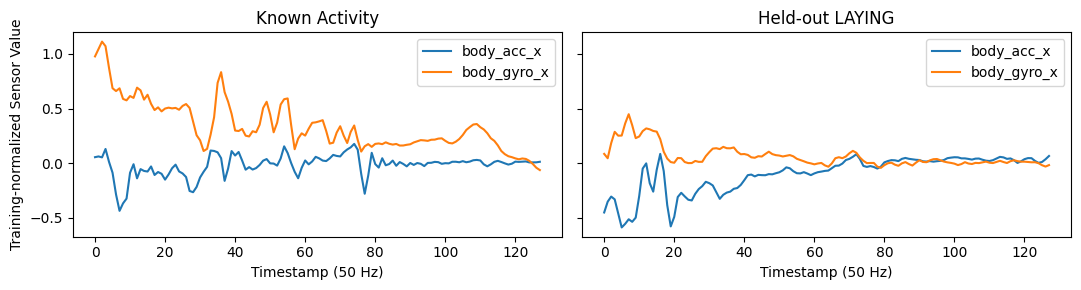

In [9]:
fig, axes = plt.subplots(1,2,figsize=(11,3),sharey=True)
for ax, sample, title in zip(axes, [known_test[0], ood_test[0]], ["Known Activity", "Held-out LAYING"]):
    ax.plot(sample[:,0],label="body_acc_x"); ax.plot(sample[:,3],label="body_gyro_x")
    ax.set_title(title); ax.set_xlabel("Timestamp (50 Hz)"); ax.legend()
axes[0].set_ylabel("Training-normalized Sensor Value")
plt.tight_layout(); plt.show()

## 5. Masked Reconstruction Model

We divide each 128-step window into 16 non-overlapping patches of 8 steps and randomly hide 50% of the patches. All nine channels in a selected patch are hidden together.

The network receives the masked signal and an explicit mask indicator, compresses them with a small fully connected encoder, and predicts the full window using a linear decoder. Loss is computed only at masked positions.

$$\mathcal{L}_{\mathrm{mask}}=\frac{\sum_{t,c}m_{t,c}(x_{t,c}-\hat{x}_{t,c})^2}{\sum_{t,c}m_{t,c}}$$

Here, $m_{t,c}=1$ denotes a hidden value. We vary only the hidden dimension to study the effect of model capacity.

In [10]:
WINDOW=128
CHANNELS=9
PATCH=8
MASK_RATIO=0.5
HIDDENS=[4,16,64]
EPOCHS=15
BATCH_SIZE=128
LEARNING_RATE=0.001

A Boolean mask marks the hidden time steps. The same time steps are masked across all sensor channels.

In [11]:
def make_masks(batch_size, device, generator=None):
    # True means hidden
    n_patches = WINDOW // PATCH
    ranks = torch.rand((batch_size,n_patches), device=device, generator=generator).argsort(dim=1)
    mask = ranks < int(n_patches*MASK_RATIO)
    return mask.repeat_interleave(PATCH, dim=1).unsqueeze(-1)

The encoder maps the flattened masked window and mask indicator into a low-dimensional representation, the decoder maps that representation back to 128 × 9 values. The reported total parameter count includes both encoder and decoder.

In [12]:
class MaskedAutoencoder(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        d = WINDOW*CHANNELS
        self.encoder = nn.Sequential(nn.Linear(d+WINDOW,hidden),nn.ReLU(),nn.Linear(hidden,hidden),nn.ReLU())
        self.decoder = nn.Linear(hidden,d)

    def forward(self, x, mask):
        masked = x.masked_fill(mask,0.0)
        z = self.encoder(torch.cat([masked.flatten(1), mask.squeeze(-1).float()],dim=1))
        return self.decoder(z).reshape_as(x)

Visible values do not contribute to the training objective. This forces the model to infer missing measurements from the observed temporal context.

In [13]:
def masked_mse(prediction, target, mask):
    weights = mask.expand_as(target).float()
    return (((prediction-target)**2)*weights).sum()/weights.sum()

## 6. Train the Three Model Capacities

Train independently on unlabeled known-activity windows using Adam and the masked MSE objective. We keep the data, masking ratio, optimizer, and number of epochs fixed so capacity is the main variable.

Training loss measures reconstruction fit on masked training windows, it does not directly measure OOD detection quality.

For each hidden dimension, initialize a new model, sample masks per batch, and optimize masked reconstruction error.

In [14]:
def train_model(hidden):
    torch.manual_seed(SEED)
    model = MaskedAutoencoder(hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train)),batch_size=BATCH_SIZE,shuffle=True)
    losses=[]
    for epoch in range(EPOCHS):
        model.train(); total=0.0; count=0
        for (batch,) in loader:
            batch=batch.to(DEVICE)
            mask=make_masks(len(batch),DEVICE)
            optimizer.zero_grad()
            loss=masked_mse(model(batch,mask),batch,mask)
            loss.backward(); optimizer.step()
            total += loss.item()*len(batch); count += len(batch)
        losses.append(total/count)
    return model,losses

Train hidden dimensions 4, 16, and 64, then visualize how masked reconstruction loss changes over epochs.

In [15]:
models={}; histories={}
for hidden in HIDDENS:
    model, history=train_model(hidden)
    models[hidden]=model; histories[hidden]=history
    params=sum(p.numel() for p in model.parameters())
    print(f"hidden={hidden:2d} | params={params:,} | final masked MSE={history[-1]:.4f}")

hidden= 4 | params=10,904 | final masked MSE=0.8521
hidden=16 | params=40,352 | final masked MSE=0.6529
hidden=64 | params=161,024 | final masked MSE=0.5290


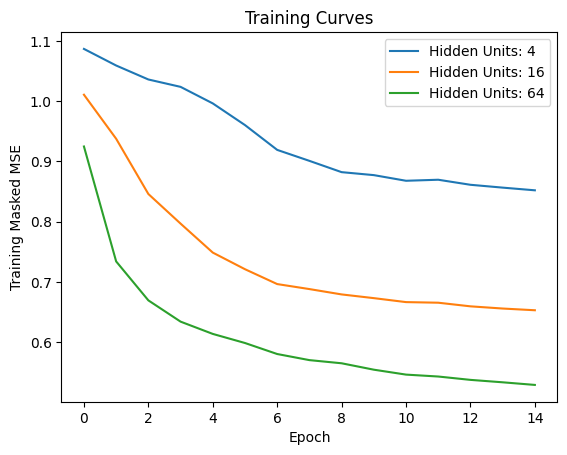

In [16]:
for hidden in HIDDENS:
    plt.plot(histories[hidden], label=f"Hidden Units: {hidden}")
plt.xlabel("Epoch")
plt.ylabel("Training Masked MSE")
plt.title("Training Curves")
plt.legend()
plt.show()

## 7. Score Known and Held-Out Activities

After training, freeze each model and score test windows using masked reconstruction error. To reduce sensitivity to any single random mask, average the per-window score over eight masking repetitions.

$$s(x)=\frac{1}{K}\sum_{k=1}^{K}\operatorname{MSE}_{\mathcal M_k}(x,\hat{x}_k),\qquad K=8$$

A larger score means the masked values were harder to reconstruct.

We evaluate AUROC and Average Precision using labels only after scoring. The notebook names AP as `AUPR`. AP depends on OOD prevalence, so interpret it alongside the test-set class balance.

Use a fixed random-number generator for evaluation masks so the capacity comparison is reproducible. Scores are calculated independently for known and OOD test windows.

In [17]:
def reconstruction_scores(model, X, repeats=8, batch_size=128):
    generator = torch.Generator(device="cpu").manual_seed(2026)
    model.eval(); outputs=[]
    with torch.no_grad():
        for start in range(0,len(X),batch_size):
            batch=torch.from_numpy(X[start:start+batch_size]).to(DEVICE)
            acc=torch.zeros(len(batch),device=DEVICE)
            for _ in range(repeats):
                mask=make_masks(len(batch),"cpu",generator=generator).to(DEVICE)
                pred=model(batch,mask)
                err=((pred-batch)**2)*mask.expand_as(batch)
                acc += err.sum(dim=(1,2))/mask.expand_as(batch).sum(dim=(1,2))
            outputs.append((acc/repeats).cpu().numpy())
    return np.concatenate(outputs)

Assign known windows label `0` and held-out LAYING windows label `1`.

In [18]:
def evaluate_model(model, hidden):
    normal_scores=reconstruction_scores(model,known_test)
    ood_scores=reconstruction_scores(model,ood_test)
    labels=np.r_[np.zeros(len(normal_scores)),np.ones(len(ood_scores))]
    scores=np.r_[normal_scores,ood_scores]
    return {"hidden":hidden,"AUROC":roc_auc_score(labels,scores),
            "AUPR":average_precision_score(labels,scores),
            "known_mean_MSE":normal_scores.mean(),"ood_mean_MSE":ood_scores.mean(),
            "parameters":sum(p.numel() for p in model.parameters())}, normal_scores,ood_scores

Report detection metrics, average reconstruction scores for both groups, and model parameter counts.

In [19]:
rows=[]; score_sets={}
for hidden,model in models.items():
    row,normal,ood=evaluate_model(model,hidden)
    rows.append(row);score_sets[hidden]=(normal,ood)
results=pd.DataFrame(rows)
display(results.round(4))

,hidden,AUROC,AUPR,known_mean_MSE,ood_mean_MSE,parameters
0,4,0.8779,0.6166,0.7830,2.0566,10904
1,16,0.7896,0.3740,0.6319,1.2983,40352
2,64,0.5573,0.1887,0.5394,0.5862,161024


## 8. Visualize and Interpret Score Separation

The histograms show whether known and held-out activity scores overlap.

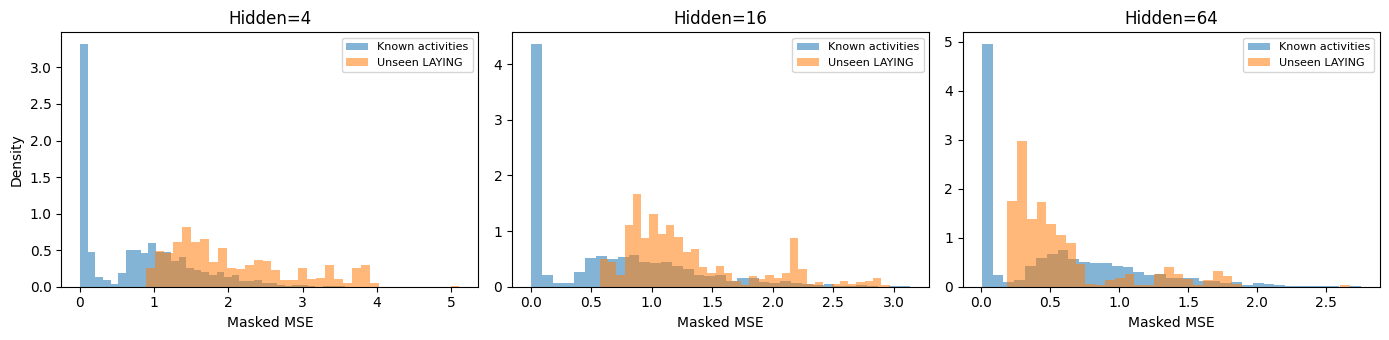

In [20]:
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
for ax,hidden in zip(axes,HIDDENS):
    known,ood=score_sets[hidden]
    ax.hist(known,bins=35,density=True,alpha=.55,label="Known activities")
    ax.hist(ood,bins=35,density=True,alpha=.55,label="Unseen LAYING")
    ax.set_title(f"Hidden={hidden}");ax.set_xlabel("Masked MSE");ax.legend(fontsize=8)
axes[0].set_ylabel("Density");plt.tight_layout();plt.show()

This experiment provides a preliminary answer to the question.

Increasing the capacity of the masked autoencoder improves reconstruction quality but reduces its ability to detect the activity excluded from training. The smallest model achieves the highest OOD detection performance, despite having the highest reconstruction error. In contrast, the largest model achieves the lowest reconstruction error but performs only slightly better than random ranking for OOD detection.

These findings suggest that better reconstruction does not necessarily imply better OOD detection, highlighting a potential trade-off between model capacity and detection performance.

Further experiments with multiple random seeds and different held-out activities are needed to determine whether this behavior generalizes.
